# Part B (04): K-Means (clustering)
K-Means is **unsupervised**: it never sees the labels while it learns.
Labels are used only afterwards, to name each cluster (cluster -> most frequent true label inside it) and to measure accuracy.


**The test set is not loaded here** (final evaluation is notebook 05).

In [1]:


from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, accuracy_score

SEED = 12
CACHE = Path("../cache")
EXP = Path("../experiments"); EXP.mkdir(exist_ok=True)

imgs = np.load(CACHE / "images_uint8.npz")
feats = np.load(CACHE / "features.npz")
CLASSES = list(imgs["classes"])

def to_raw(X):
    return X.reshape(len(X), -1).astype(np.float32) / 255.0

FS = {
    "raw":  (to_raw(imgs["X_train"]), to_raw(imgs["X_val"])),
    "hist": (feats["H_train"], feats["H_val"]),
    "pca":  (feats["P_train"], feats["P_val"]),
}
y_train, y_val = feats["y_train"], feats["y_val"]

## 
Helper: cluster -> label mapping
For every cluster, count the true labels of the **train** images inside it and give the cluster the most frequent one.

In [2]:
def cluster_label_map(clusters, y, k):
    mapping = {}
    for c in range(k):
        members = clusters == c
        mapping[c] = int(np.bincount(y[members], minlength=len(CLASSES)).argmax()) if members.any() else -1
    return mapping

def apply_map(clusters, mapping):
    return np.array([mapping[c] for c in clusters])

def safe_silhouette(X, labels):
    
    return silhouette_score(X, labels) if len(set(labels)) >= 2 else float("nan")

## Experiment: number of clusters x feature set
`n_clusters = 5` matches the number of classes. Larger values are shown for comparison only: more clusters make the
accuracy go up almost by construction (each cluster can specialize), so they are not a fair comparison with the classifiers.

Silhouette (-1 to 1) measures how well separated the clusters are, with no labels involved.
We also compute the Silhouette of the **true classes** in the same feature space, to see how separable the classes are at all.

In [3]:
N_CLUSTERS = [5, 10, 15, 20]
rows = []

for name, (Xtr, Xva) in FS.items():
    sil_true = safe_silhouette(Xtr, y_train)         
    for k in N_CLUSTERS:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xtr)
        c_tr, c_va = km.labels_, km.predict(Xva)
        mp = cluster_label_map(c_tr, y_train, k)
        rows.append({
            "features": name, "n_clusters": k,
            "train_acc": accuracy_score(y_train, apply_map(c_tr, mp)),
            "val_acc": accuracy_score(y_val, apply_map(c_va, mp)),
            "silhouette_train": safe_silhouette(Xtr, c_tr),
            "silhouette_val": safe_silhouette(Xva, c_va),
            "silhouette_true_labels": sil_true,
            "classes_covered": len(set(mp.values())),
        })
    print("done:", name)

km_results = pd.DataFrame(rows)
print(km_results.round(4).to_string(index=False))
km_results.to_csv(EXP / "kmeans_part_b.csv", index=False)

done: raw
done: hist
done: pca
features  n_clusters  train_acc  val_acc  silhouette_train  silhouette_val  silhouette_true_labels  classes_covered
     raw           5     0.2996   0.1037            0.1540          0.1556                 -0.0326                4
     raw          10     0.3333   0.1505            0.0840          0.0984                 -0.0326                5
     raw          15     0.3693   0.2074            0.0747          0.0727                 -0.0326                5
     raw          20     0.3642   0.1438            0.0806          0.0756                 -0.0326                5
    hist           5     0.2687   0.1472            0.1431          0.1533                 -0.0370                4
    hist          10     0.3150   0.1639            0.1857          0.2106                 -0.0370                5
    hist          15     0.3333   0.1773            0.1872          0.2216                 -0.0370                5
    hist          20     0.3502   0.1973 


## Cluster vs true label table (train, n_clusters = 5)
Rows are clusters, columns are the true classes. A clean K-Means result would put each class mostly in one row.

true class    5   10   20   50  100
cluster                            
0           138  104  144  138  172
1            20   25    2   11   22
2            23   52   46   24   26
3             2   17   30   25    5
4            87   82   38   74   55
mapping: {0: np.str_('100'), 1: np.str_('10'), 2: np.str_('10'), 3: np.str_('20'), 4: np.str_('5')}
classes covered: 4 of 5


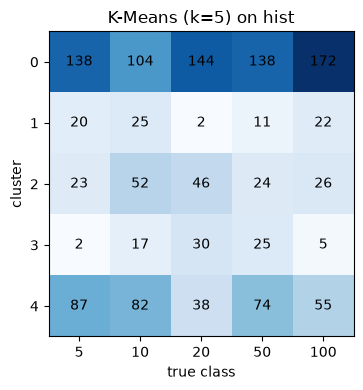

In [4]:

FEATURE = "hist"           
Xtr, Xva = FS[FEATURE]
km = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(Xtr)
mp = cluster_label_map(km.labels_, y_train, 5)

ct = pd.crosstab(pd.Series(km.labels_, name="cluster"),
                 pd.Series([CLASSES[i] for i in y_train], name="true class"))
ct = ct[[c for c in CLASSES if c in ct.columns]]
print(ct)
print("mapping:", {c: CLASSES[l] for c, l in mp.items()})
print("classes covered:", len(set(mp.values())), "of", len(CLASSES))

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(ct.values, cmap="Blues")
ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns)
ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, ct.values[i, j], ha="center", va="center")
ax.set_xlabel("true class"); ax.set_ylabel("cluster"); ax.set_title(f"K-Means (k=5) on {FEATURE}")
plt.tight_layout(); plt.show()